# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:**
- **Student ID:**
- **Section:**
- **GitHub:**
- **Kaggle:**
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
import warnings; warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 100

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [2]:
df = pd.read_csv('Mall_Customers.csv')   # upload the CSV next to the notebook (Colab: left panel > Files)
df = df.rename(columns={'Genre': 'Gender',                  # some copies of the file use 'Genre'
                        'Annual Income (k$)': 'Income',
                        'Spending Score (1-100)': 'Spending'})
print('Shape            :', df.shape)
print('Missing values   :', int(df.isna().sum().sum()))
print('Duplicate rows   :', int(df.duplicated().sum()))
print('Gender counts    :\n', df['Gender'].value_counts())
df[['Age', 'Income', 'Spending']].describe().round(2)

Shape            : (200, 5)
Missing values   : 0
Duplicate rows   : 0
Gender counts    :
 Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


> **Interpretation:** The data is clean: 200 customers, 0 missing values, 0 duplicate rows, 112 women (56%) and 88 men (44%). Age is 18-70 (mean 38.9, std 14.0), Income 15-137 k$ (mean 60.6, std 26.3) and Spending 1-99 (mean 50.2, std 25.8). Income and Spending have a similar spread, so they can be used together without scaling in Parts 2, 3, 5 and 6; Part 4 shows why scaling is needed when features have different sizes.

### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


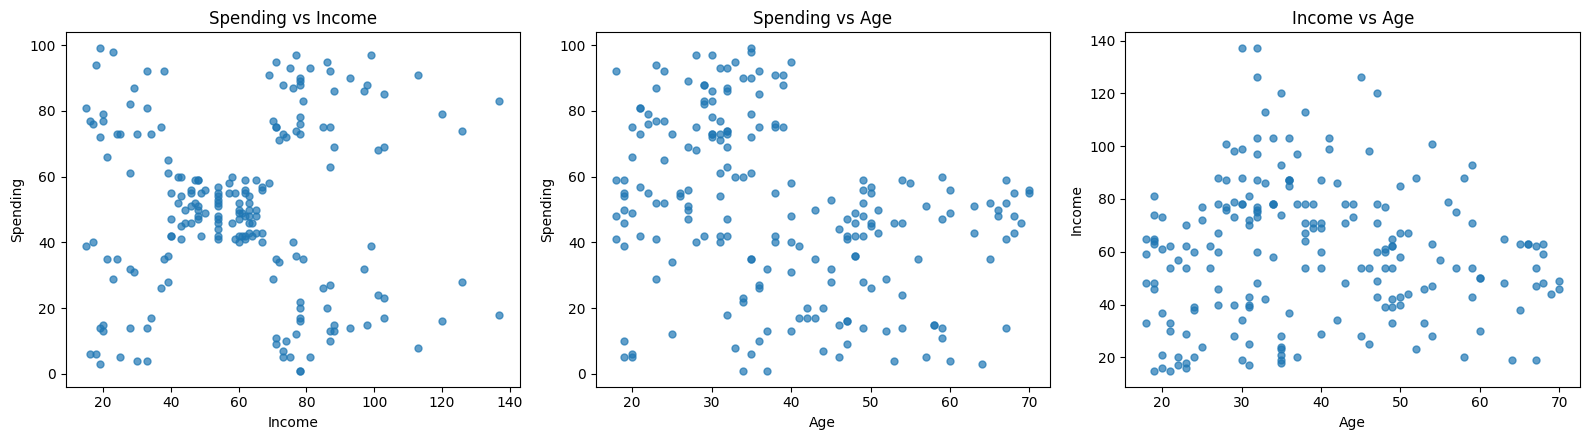

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
pairs = [('Income', 'Spending'), ('Age', 'Spending'), ('Age', 'Income')]   # (x, y)
for a, (xc, yc) in zip(ax, pairs):
    a.scatter(df[xc], df[yc], s=25, alpha=0.7)
    a.set_xlabel(xc); a.set_ylabel(yc); a.set_title(f'{yc} vs {xc}')
plt.tight_layout(); plt.show()

> **Interpretation:** Spending vs Income shows five compact blobs (the four corners and the centre), so it is the best plot for clustering. Spending vs Age has only a weak pattern (correlation -0.33: customers aged 40+ have a mean Spending of 36.8 while younger customers range from 1 to 99). Income vs Age is one cloud (correlation -0.01). We therefore expect K = 5 on Income and Spending.

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

**(a)** *Spending vs Income:* **5 groups**, clearly separated (low income/low spending, low income/high spending, a big centre group, high income/low spending, high income/high spending). *Spending vs Age:* only a loose pattern (correlation = -0.33): customers aged 40+ (84 people) have a mean Spending of only 36.8, while customers under 40 spread from 1 to 99, so at most about 2 vague, overlapping groups. *Income vs Age:* **one cloud, no groups** (correlation = -0.01). **Spending vs Income** shows the groups most clearly.

**(b)** Accuracy needs a correct answer (a target column) to compare against, and a train/test split exists to test predictions of that target on unseen rows. Mall Customers has no target: nobody knows the 'right' group of customer 1, so there is nothing to score. A clustering is judged by how tight and separated the groups are (inertia, silhouette), by plots and by whether the groups make business sense.

---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [4]:
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
m = np.array([4.0, 11.0])                                  # starting centroids
it = 0
while True:
    it += 1
    dist = np.abs(x[:, None] - m[None, :])                 # shape (9, 2)
    lab = dist.argmin(axis=1)                              # assign step
    new_m = np.array([x[lab == k].mean() for k in range(2)])   # update step
    print(f'Iteration {it}: C1 = {x[lab==0].astype(int).tolist()}   C2 = {x[lab==1].astype(int).tolist()}   '
          f'-> new centroids = {new_m}')
    if np.allclose(new_m, m):                              # convergence
        break
    m = new_m
inertia1 = ((x - m[lab]) ** 2).sum()
print('\nFinal centroids:', m, '| Inertia:', inertia1)
print('Matches lecture (7, 25, 150)?', np.allclose(m, [7, 25]) and np.isclose(inertia1, 150))

Iteration 1: C1 = [2, 4, 3]   C2 = [10, 12, 20, 30, 11, 25]   -> new centroids = [ 3. 18.]
Iteration 2: C1 = [2, 4, 10, 3]   C2 = [12, 20, 30, 11, 25]   -> new centroids = [ 4.75 19.6 ]
Iteration 3: C1 = [2, 4, 10, 12, 3, 11]   C2 = [20, 30, 25]   -> new centroids = [ 7. 25.]
Iteration 4: C1 = [2, 4, 10, 12, 3, 11]   C2 = [20, 30, 25]   -> new centroids = [ 7. 25.]

Final centroids: [ 7. 25.] | Inertia: 150.0
Matches lecture (7, 25, 150)? True


> **Interpretation:** The centroids move (4, 11) -> (3, 18) -> (4.75, 19.6) -> (7, 25) and stay at (7, 25) in iteration 4, which only confirms convergence. Final inertia = (25+9+9+25+16+16) + (25+25+0) = 100 + 50 = **150**, exactly as in the lecture slides.

### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [5]:
P = np.array([[185, 72], [170, 56], [168, 60], [179, 68], [182, 72], [188, 77]], dtype=float)
M = P[[0, 1]].copy()                                       # start with P1 and P2
it = 0
while True:
    it += 1
    D = np.sqrt(((P[:, None, :] - M[None, :, :]) ** 2).sum(axis=2))   # (6, 2) Euclidean
    lab = D.argmin(axis=1)
    new_M = np.array([P[lab == k].mean(axis=0) for k in range(2)])
    print(f'Iteration {it}: clusters = {["C"+str(l+1) for l in lab]}')
    print(f'            centroids M1 = {M[0].round(2)}, M2 = {M[1].round(2)}')
    if it == 1:
        print('            distance table (iteration 1):')
        print(pd.DataFrame(D.round(2), index=[f'P{i+1}' for i in range(6)], columns=['d(M1)', 'd(M2)']).to_string())
    if np.allclose(new_M, M):
        break
    M = new_M
print('\nFinal distance table:')
print(pd.DataFrame(D.round(2), index=[f'P{i+1}' for i in range(6)], columns=['d(M1)', 'd(M2)']).to_string())
print('\nFinal centroids:', M.round(2).tolist(), '| iterations:', it)
# hand check of d(P3, M2) in iteration 1: P3 = (168, 60), M2 = P2 = (170, 56)
print('Hand check d(P3,M2) =', round(np.sqrt((168 - 170) ** 2 + (60 - 56) ** 2), 2))

Iteration 1: clusters = ['C1', 'C2', 'C2', 'C1', 'C1', 'C1']
            centroids M1 = [185.  72.], M2 = [170.  56.]
            distance table (iteration 1):
    d(M1)  d(M2)
P1   0.00  21.93
P2  21.93   0.00
P3  20.81   4.47
P4   7.21  15.00
P5   3.00  20.00
P6   5.83  27.66
Iteration 2: clusters = ['C1', 'C2', 'C2', 'C1', 'C1', 'C1']
            centroids M1 = [183.5   72.25], M2 = [169.  58.]

Final distance table:
    d(M1)  d(M2)
P1   1.52  21.26
P2  21.13   2.24
P3  19.76   2.24
P4   6.19  14.14
P5   1.52  19.10
P6   6.54  26.87

Final centroids: [[183.5, 72.25], [169.0, 58.0]] | iterations: 2
Hand check d(P3,M2) = 4.47


> **Interpretation:** P1, P4, P5, P6 (tall and heavy) form C1 and P2, P3 form C2. Centroids end at M1 = (183.5, 72.25) and M2 = (169, 58) after 2 iterations (the second confirms convergence). The hand check d(P3, M2) = sqrt((168-170)^2 + (60-56)^2) = sqrt(20) = **4.47**, matching both the code and the lecture.

### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [6]:
def my_kmeans(X, init_centroids, max_iter=100):
    """K-Means from scratch. Returns labels, centroids, inertia, n_iterations."""
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    C = np.asarray(init_centroids, dtype=float).reshape(len(init_centroids), -1).copy()
    for it in range(1, max_iter + 1):
        D = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))   # distances (n, K)
        labels = D.argmin(axis=1)                                         # assign
        new_C = C.copy()                                                  # empty cluster keeps old centroid
        for k in range(len(C)):
            if (labels == k).any():
                new_C[k] = X[labels == k].mean(axis=0)                    # update
        if np.allclose(new_C, C):                                         # converged
            break
        C = new_C
    inertia = ((X - C[labels]) ** 2).sum()
    return labels, C, inertia, it

In [7]:
lab, C, inert, n_it = my_kmeans(x, [4, 11])
print('Example 1 -> centroids:', C.ravel(), '| inertia:', inert, '| iterations:', n_it)

Example 1 -> centroids: [ 7. 25.] | inertia: 150.0 | iterations: 4


> **Interpretation:** `my_kmeans` returns the centroids 7 and 25 and the inertia 150 in 4 iterations, the same as the lecture and as the loop in Task 1.1. An empty cluster simply keeps its old centroid.

### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [8]:
X2 = df[['Income', 'Spending']].values.astype(float)       # 200 x 2
init5 = X2[:5].copy()
lab_me, C_me, in_me, it_me = my_kmeans(X2, init5)
km = KMeans(n_clusters=5, init=init5, n_init=1, tol=0, algorithm='lloyd').fit(X2)
print(f'Iterations : mine = {it_me}, sklearn = {km.n_iter_}')
print(f'Inertia    : mine = {in_me:.4f}, sklearn = {km.inertia_:.4f}')
print('Labels identical    :', np.array_equal(lab_me, km.labels_))
print('Centroids identical :', np.allclose(C_me, km.cluster_centers_))
print('Max centroid difference:', np.abs(C_me - km.cluster_centers_).max())

Iterations : mine = 4, sklearn = 4
Inertia    : mine = 44448.4554, sklearn = 44448.4554
Labels identical    : True
Centroids identical : True
Max centroid difference: 2.842170943040401e-14


> **Interpretation:** Same iterations (4), same inertia (44448.4554), identical labels and identical centroids (difference 2.8e-14, floating-point rounding only). My function is equivalent to scikit-learn's Lloyd algorithm.

**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

**(a)** In iteration 1 the centroids are 4 and 11, so for the point 10: |10-4| = 6 and |10-11| = 1, so it goes to C2. After the update step the centroids become 3 (C1 = {2, 4, 3}) and 18 (C2 = {10, 12, 20, 30, 11, 25}), because 20, 30 and 25 pulled the C2 centroid up. In iteration 2: |10-3| = 7 and |10-18| = 8, so 10 is now nearer to C1 and moves there.

**(b)** The loop stops when the update step leaves **every centroid unchanged** (no point changes cluster); in Example 1 this happens at iteration 4, which only confirms the centroids 7 and 25. Stopping is guaranteed because each assign step and each update step can only lower the inertia or keep it, never raise it, and there is only a finite number of ways to split the points into K groups, so the algorithm cannot cycle forever. But it stops at the first solution it cannot improve, which depends on the starting centroids, so it can be a local minimum and not the best answer (see Part 3).

**(c)** Yes. Iterations: mine = 4, sklearn = 4. Inertia: 44448.4554 for both. Labels: identical. Centroids: identical (largest difference 2.8e-14, which is only floating-point rounding). The reason is that with the same starting centroids, `tol=0` and `algorithm='lloyd'`, scikit-learn runs the same assign/update loop as my function.

**(d)** A centroid is the **average customer** of the group, for example the cluster of rich low-spenders has the centroid (Income = 88.2, Spending = 17.1). It is a point, not necessarily a real customer. Features must be numeric because K-Means subtracts, squares and averages the values to compute distances and centroids, and you cannot do this with text such as 'Male' / 'Female'.

---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


,Inertia,Silhouette,Drop from K-1
K,,,
2,181363.5960,0.2969,NaN
3,106348.3731,0.4676,75015.2
4,73679.7890,0.4932,32668.6
5,44448.4554,0.5539,29231.3
6,37233.8145,0.5398,7214.6
7,30241.3436,0.5288,6992.5
8,25036.4176,0.4548,5204.9
9,21916.7948,0.4561,3119.6
10,20072.0709,0.4411,1844.7


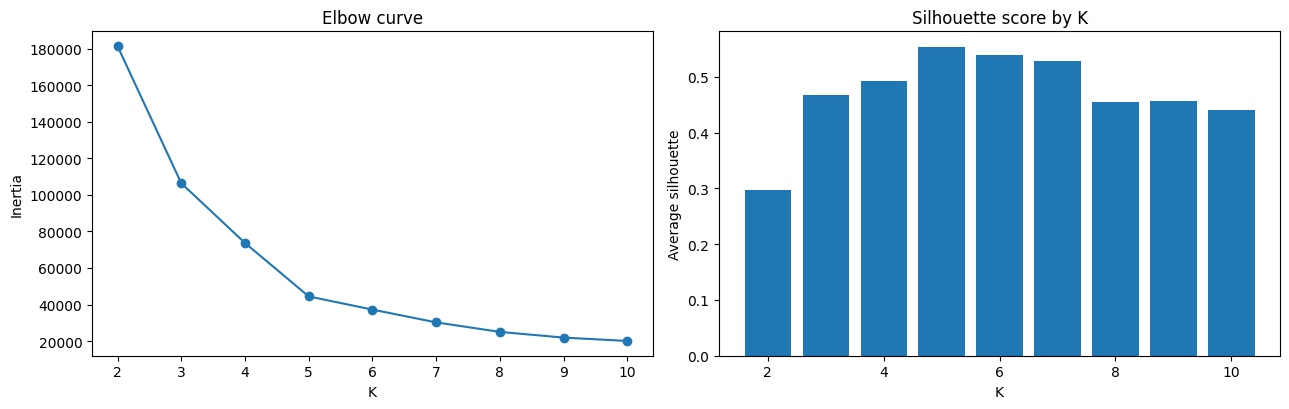

K with the highest silhouette: 5 -> 0.5539


In [9]:
rows = []
for k in range(2, 11):
    mk = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    rows.append((k, mk.inertia_, silhouette_score(X2, mk.labels_)))
tab = pd.DataFrame(rows, columns=['K', 'Inertia', 'Silhouette']).set_index('K')
tab['Drop from K-1'] = (-tab['Inertia'].diff()).round(1)
display(tab.round(4))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(tab.index, tab['Inertia'], 'o-'); ax[0].set_xlabel('K'); ax[0].set_ylabel('Inertia'); ax[0].set_title('Elbow curve')
ax[1].bar(tab.index, tab['Silhouette']); ax[1].set_xlabel('K'); ax[1].set_ylabel('Average silhouette'); ax[1].set_title('Silhouette score by K')
plt.tight_layout(); plt.show()
print('K with the highest silhouette:', int(tab['Silhouette'].idxmax()), '->', round(tab['Silhouette'].max(), 4))

> **Interpretation:** Inertia always falls, but the drop becomes small after K = 5 (29,231 from K=4 to 5, then only 7,215 from 5 to 6): the elbow is at K = 5. The silhouette bars peak at K = 5 (0.5539). Both tools agree on K = 5.

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [10]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
lab5 = km5.labels_

def sil_point(X, labels, i):
    """a, b, s for point i using only NumPy distances."""
    d = np.sqrt(((X - X[i]) ** 2).sum(axis=1))             # distance from point i to all points
    own = labels == labels[i]
    a = d[own].sum() / (own.sum() - 1)                     # mean distance to the OTHER points of its cluster
    b = min(d[labels == k].mean() for k in np.unique(labels) if k != labels[i])   # nearest other cluster
    return a, b, (b - a) / max(a, b)

a, b, s = sil_point(X2, lab5, 0)
s_all = silhouette_samples(X2, lab5)
print(f'Customer 1 by hand: a = {a:.4f}, b = {b:.4f}, s = {s:.4f}')
print(f'silhouette_samples : s = {s_all[0]:.4f}')

prof = pd.DataFrame({'Cluster': lab5, 's': s_all}).groupby('Cluster')['s'].agg(['count', 'mean', 'min']).round(4)
display(prof)
print('Customers with negative silhouette:', int((s_all < 0).sum()))

Customer 1 by hand: a = 24.6404, b = 42.2653, s = 0.4170
silhouette_samples : s = 0.4170


,count,mean,min
Cluster,,,
0,81,0.5967,0.1153
1,39,0.5092,0.2254
2,22,0.5990,0.0507
3,35,0.5040,-0.0234
4,23,0.5123,-0.0093


Customers with negative silhouette: 2


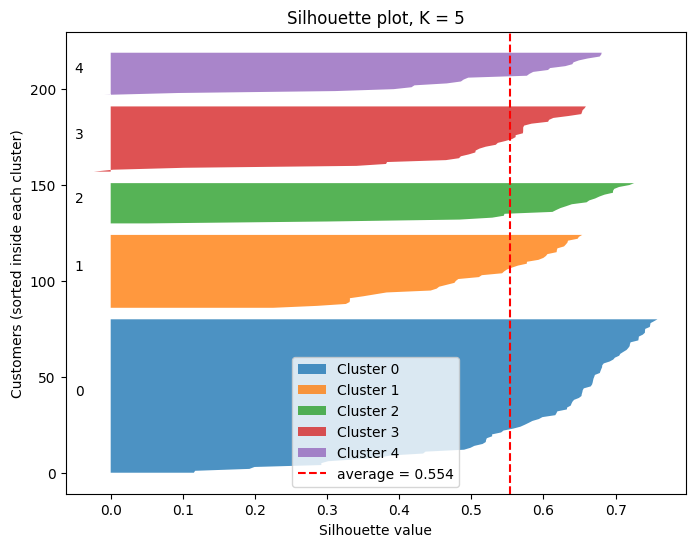

In [11]:
fig, ax = plt.subplots(figsize=(8, 6)); y0 = 0
for k in range(5):
    sk = np.sort(s_all[lab5 == k])
    ax.fill_betweenx(np.arange(y0, y0 + len(sk)), 0, sk, alpha=0.8, label=f'Cluster {k}')
    ax.text(-0.05, y0 + len(sk) / 2, str(k)); y0 += len(sk) + 5
ax.axvline(s_all.mean(), color='red', ls='--', label=f'average = {s_all.mean():.3f}')
ax.set_xlabel('Silhouette value'); ax.set_ylabel('Customers (sorted inside each cluster)')
ax.set_title('Silhouette plot, K = 5'); ax.legend(); plt.show()

> **Interpretation:** For K = 5 the average silhouette is 0.5539. Customer 1 has s = 0.417 by hand and in `silhouette_samples` (a = 24.64, b = 42.27). The mean silhouette per cluster is between 0.50 and 0.60 (weakest: Cluster 3, 0.5040), and only 2 of 200 customers are negative (-0.0234 and -0.0093, both on cluster borders). In the plot all clusters are mostly wide positive bars: a good clustering.

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [12]:
pts = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float)
lab_p, C_p, in_p, it_p = my_kmeans(pts, [1, 11])
print('Cluster of each point :', dict(zip(pts.astype(int).tolist(), (lab_p + 1).tolist())))
print('Final clusters        : C1 =', pts[lab_p == 0].astype(int).tolist(), ' C2 =', pts[lab_p == 1].astype(int).tolist())
print('Final centroids       :', C_p.ravel(), '| inertia:', in_p, '| iterations:', it_p)
Xp = pts.reshape(-1, 1)
sp = silhouette_samples(Xp, lab_p)
for p in [1, 7, 11]:
    i = int(np.where(pts == p)[0][0])
    a, b, s = sil_point(Xp, lab_p, i)
    print(f'Point {p:>2}: a = {a:.3f}, b = {b:.3f}, s = {s:.3f}  | silhouette_samples = {sp[i]:.3f}')

Cluster of each point : {1: 1, 3: 1, 5: 1, 7: 1, 11: 2, 13: 2, 15: 2}
Final clusters        : C1 = [1, 3, 5, 7]  C2 = [11, 13, 15]
Final centroids       : [ 4. 13.] | inertia: 28.0 | iterations: 3
Point  1: a = 4.000, b = 12.000, s = 0.667  | silhouette_samples = 0.667
Point  7: a = 4.000, b = 6.000, s = 0.333  | silhouette_samples = 0.333
Point 11: a = 3.000, b = 7.000, s = 0.571  | silhouette_samples = 0.571


> **Interpretation:** Final clusters C1 = {1, 3, 5, 7} and C2 = {11, 13, 15}, centroids 4 and 13, inertia 28, after 3 iterations. By hand and by `silhouette_samples`: point 1 s = 0.667 (a=4, b=12), point 7 s = 0.333 (a=4, b=6), point 11 s = 0.571 (a=3, b=7). Point 7 is the least well placed because it is at the edge of C1.

**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

**(a)** The **elbow** suggests **K = 5**: the inertia falls by 75,015 (K=2 to 3), 32,669 (3 to 4) and 29,231 (4 to 5), but only by 7,215 from K=5 to 6 and 6,993 from 6 to 7, so the bend is at 5. The **silhouette** is highest at **K = 5** (0.5539; K=6 gives 0.5398, K=4 gives 0.4932). Yes, they agree.

**(b)** Customer 1 (Income 15, Spending 39) has a = 24.64, b = 42.27 and **s = 0.417** (same as `silhouette_samples`). Positive and clearly above 0: the customer is closer to its own cluster (24.6) than to the nearest other cluster (42.3), so it is reasonably well placed, though not a perfect fit (1.0). The weakest average silhouette is **Cluster 3** (mean 0.5040, 35 customers, the high income/low spending group). **2 customers** have a negative silhouette (Cluster 3: minimum -0.0234, Cluster 4: minimum -0.0093); they sit on the border between two clusters.

**(c)** **Point 7 is less well placed.** Both points have a = 4.0 (average distance to the other points of C1 = {1, 3, 5, 7}). For point 1, b = 12.0 so s = (12-4)/12 = 0.667. For point 7, b = 6.0 (average distance to 11, 13, 15), so s = (6-4)/6 = 0.333. Point 7 sits at the edge of C1, close to C2, so the gap between a and b is small. (Point 11: a = 3, b = 7, s = 0.571.)

**(d)** Inertia **always decreases when K grows** (it is 0 when K equals the number of points), so the lowest inertia would always pick the largest K and give meaningless tiny clusters. Here K=10 has inertia 20,072 against 44,448 for K=5, but its silhouette is lower (0.4411 against 0.5539). We must look for the bend in the elbow and also check the silhouette.

---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


,Distinct inertias,Lowest,Highest,% runs at best
Setting,,,,
"random, n_init=1",14,44448.5,91762.0,33.3
"k-means++, n_init=1",6,44448.5,66733.4,60.0
"k-means++, n_init=10",1,44448.5,44448.5,100.0


Best inertia overall: 44448.5


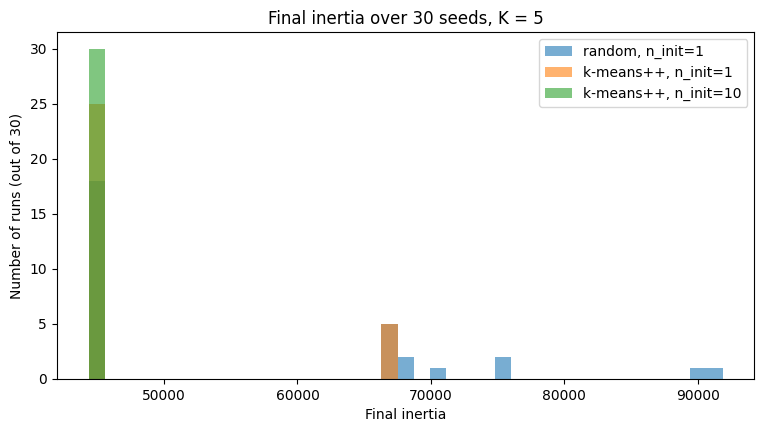

{'random, n_init=1': [44448.5, 44454.5, 66532.0, 66674.4, 66698.1, 66733.4, 66790.3, 67789.3, 67818.5, 70096.4, 75036.5, 75582.7, 89897.5, 91762.0], 'k-means++, n_init=1': [44448.5, 44454.5, 66465.1, 66532.6, 66674.4, 66733.4], 'k-means++, n_init=10': [44448.5]}


In [13]:
settings = {'random, n_init=1':      dict(init='random',    n_init=1),
            'k-means++, n_init=1':   dict(init='k-means++', n_init=1),
            'k-means++, n_init=10':  dict(init='k-means++', n_init=10)}
res = {name: [KMeans(n_clusters=5, random_state=r, **kw).fit(X2).inertia_ for r in range(30)]
       for name, kw in settings.items()}
best = round(min(min(v) for v in res.values()), 1)
rows = []
for name, v in res.items():
    v = np.round(v, 1)
    rows.append((name, len(np.unique(v)), v.min(), v.max(), 100 * np.mean(v == best)))
t31 = pd.DataFrame(rows, columns=['Setting', 'Distinct inertias', 'Lowest', 'Highest', '% runs at best']).set_index('Setting')
display(t31.round(1))
print('Best inertia overall:', best)
plt.figure(figsize=(9, 4.5))
allv = np.concatenate([np.round(v, 1) for v in res.values()])
bins = np.linspace(allv.min() - 100, allv.max() + 100, 40)
for name, v in res.items():
    plt.hist(v, bins=bins, alpha=0.6, label=name)
plt.xlabel('Final inertia'); plt.ylabel('Number of runs (out of 30)'); plt.title('Final inertia over 30 seeds, K = 5')
plt.legend(); plt.show()
print({k: sorted(set(np.round(v, 1).tolist())) for k, v in res.items()})

> **Interpretation:** Random starts gave 14 different inertia values (only 33.3% best, worst 91,762.0, more than twice the best 44,448.5). k-means++ with one start gave 6 values (60.0% best). k-means++ with `n_init=10` gave a single value, 44,448.5, in 100% of the 30 seeds. The histogram shows the random setting spread over many bad local minima, and `n_init=10` in one bar at the best value.

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


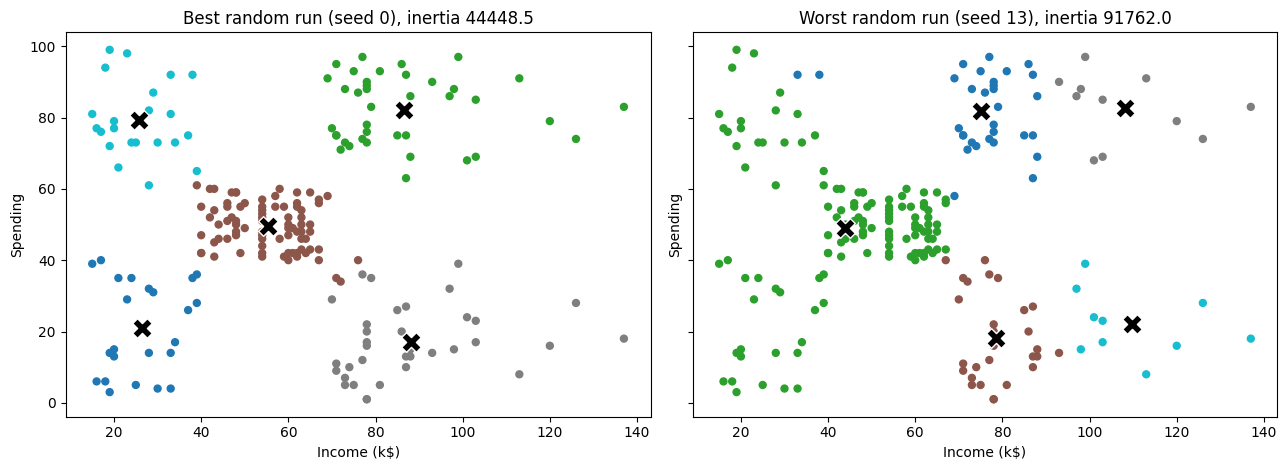

Best  inertia = 44448.5
Worst inertia = 91762.0
ARI(best, worst) = 0.4553
Worst-run centroids (Income, Spending):
 [[ 43.9  49.1]
 [ 75.   81.8]
 [ 78.5  18.2]
 [108.2  82.7]
 [109.7  22. ]]
Best-run centroids  (Income, Spending):
 [[25.7 79.4]
 [26.3 20.9]
 [55.3 49.5]
 [86.5 82.1]
 [88.2 17.1]]


In [14]:
v = np.array(res['random, n_init=1'])
seed_best, seed_worst = int(v.argmin()), int(v.argmax())
mb = KMeans(n_clusters=5, init='random', n_init=1, random_state=seed_best).fit(X2)
mw = KMeans(n_clusters=5, init='random', n_init=1, random_state=seed_worst).fit(X2)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True, sharey=True)
for a_, mm, tt in zip(ax, [mb, mw], [f'Best random run (seed {seed_best}), inertia {mb.inertia_:.1f}',
                                      f'Worst random run (seed {seed_worst}), inertia {mw.inertia_:.1f}']):
    a_.scatter(X2[:, 0], X2[:, 1], c=mm.labels_, cmap='tab10', s=25)
    a_.scatter(*mm.cluster_centers_.T, c='black', marker='X', s=200, edgecolor='white')
    a_.set_title(tt); a_.set_xlabel('Income (k$)'); a_.set_ylabel('Spending')
plt.tight_layout(); plt.show()
print(f'Best  inertia = {mb.inertia_:.1f}\nWorst inertia = {mw.inertia_:.1f}')
print('ARI(best, worst) =', round(adjusted_rand_score(mb.labels_, mw.labels_), 4))
print('Worst-run centroids (Income, Spending):\n', mw.cluster_centers_[np.argsort(mw.cluster_centers_[:, 0])].round(1))
print('Best-run centroids  (Income, Spending):\n', mb.cluster_centers_[np.argsort(mb.cluster_centers_[:, 0])].round(1))

> **Interpretation:** The best random run has inertia 44,448.5 and finds the five natural groups. The worst has inertia 91,762.0: it puts the three low/centre groups into one cluster (centroid (43.9, 49.1)) and splits each high-income group into two (centroids (75.0, 81.8) and (108.2, 82.7); (78.5, 18.2) and (109.7, 22.0)). ARI between them is only 0.4553, so a bad start gives a really different (and worse) segmentation.

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

**(a)** `init='random', n_init=1` produced **14 different** final inertia values and only **33.3%** of the runs (10 of 30) reached the best inertia (44,448.5); its worst run was 91,762.0. `k-means++, n_init=1` gave **6 different** values and **60.0%** (18 of 30) reached the best. `k-means++, n_init=10` gave **1 value** and **100.0%** of runs reached the best.

**(b)** K-Means only improves the answer step by step from where it starts and stops at the first solution it cannot improve (a local minimum). Different starting centroids lead to different local minima, so the same data and the same K can give different answers (for example two starting centroids in one group, and none in another).

**(c)** k-means++ chooses starting centroids that are far from each other, so bad starts become rarer (60% best runs against 33.3%). `n_init` repeats the whole algorithm with different starts and keeps the run with the lowest inertia, so one lucky start is enough. With `n_init=10` all 30 seeds gave the same best inertia 44,448.5 (100%).

**(d)** Cluster numbers are arbitrary: the group called cluster 2 in one run may be called cluster 4 in another, so comparing the label numbers would say two identical clusterings are different. ARI compares whether pairs of customers are grouped together or apart, ignoring the numbers: 1 means identical groups, about 0 means no better than random. (Best vs worst random run: ARI = 0.4553.)

---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


ARI raw k$     vs raw dollars    : 0.4897
ARI scaled k$  vs scaled dollars : 1.0
ARI raw dollars vs scaled dollars: 0.3605
ARI raw k$     vs scaled k$      : 0.7701


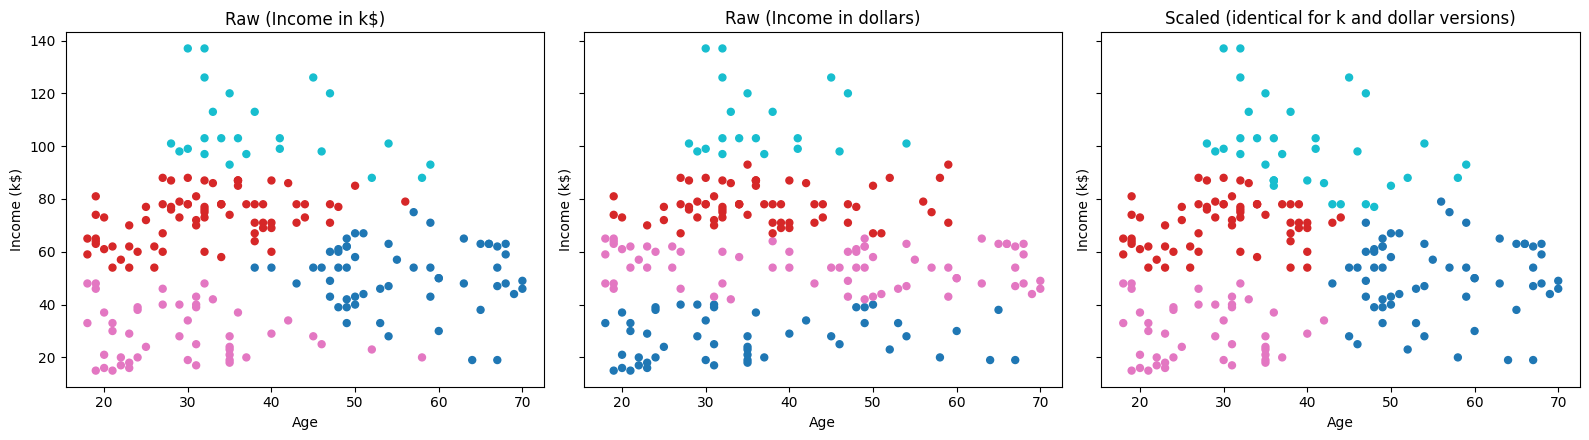

Age range: 18.0 - 70.0 | Income range (k$): 15.0 - 137.0


In [15]:
AI_k = df[['Age', 'Income']].values.astype(float)
AI_d = AI_k.copy(); AI_d[:, 1] *= 1000                      # Income in dollars
def fit4(X):
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X).labels_
l_rk = fit4(AI_k)
l_rd = fit4(AI_d)
l_sk = fit4(StandardScaler().fit_transform(AI_k))
l_sd = fit4(StandardScaler().fit_transform(AI_d))
print('ARI raw k$     vs raw dollars    :', round(adjusted_rand_score(l_rk, l_rd), 4))
print('ARI scaled k$  vs scaled dollars :', round(adjusted_rand_score(l_sk, l_sd), 4))
print('ARI raw dollars vs scaled dollars:', round(adjusted_rand_score(l_rd, l_sd), 4))
print('ARI raw k$     vs scaled k$      :', round(adjusted_rand_score(l_rk, l_sk), 4))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for a_, l, tt in zip(ax, [l_rk, l_rd, l_sk], ['Raw (Income in k$)', 'Raw (Income in dollars)', 'Scaled (identical for k and dollar versions)']):
    a_.scatter(AI_k[:, 0], AI_k[:, 1], c=l, cmap='tab10', s=25)
    a_.set_title(tt); a_.set_xlabel('Age'); a_.set_ylabel('Income (k$)')
plt.tight_layout(); plt.show()
# range of each column in the raw k$ and dollars version
print('Age range:', AI_k[:, 0].min(), '-', AI_k[:, 0].max(), '| Income range (k$):', AI_k[:, 1].min(), '-', AI_k[:, 1].max())

> **Interpretation:** Raw k$ and raw dollars give different clusters (ARI 0.4897), while the scaled versions are identical (ARI 1.0). Raw dollars versus scaled dollars is only 0.3605. In the plots, the dollar version cuts the data into four horizontal Income bands and ignores Age completely; the raw k$ version mixes Age and Income, but Income still has the larger influence (its spread is larger); the scaled version gives both features the same weight.

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [16]:
wine = load_wine()
Xw, yw = wine.data, wine.target
sd = pd.Series(Xw.std(axis=0), index=wine.feature_names).sort_values(ascending=False)
print('Three largest std:\n', sd.head(3).round(3).to_string())
print('Smallest std:\n', sd.tail(1).round(4).to_string())

Three largest std:
 proline              314.022
magnesium             14.242
alcalinity_of_ash      3.330
Smallest std:
 nonflavanoid_phenols    0.1241


In [17]:
Xw_s = StandardScaler().fit_transform(Xw)
out = []
for name, XX in [('Raw', Xw), ('Scaled', Xw_s)]:
    kmw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(XX)
    out.append((name, adjusted_rand_score(yw, kmw.labels_), silhouette_score(XX, kmw.labels_),
                np.bincount(kmw.labels_).tolist()))
    if name == 'Raw': lab_wr = kmw.labels_
    else: lab_ws = kmw.labels_
display(pd.DataFrame(out, columns=['Data', 'ARI vs true cultivar', 'Silhouette', 'Cluster sizes']).set_index('Data').round(4))
print('True cultivar sizes:', np.bincount(yw).tolist())

,ARI vs true cultivar,Silhouette,Cluster sizes
Data,,,
Raw,0.3711,0.5711,"[62, 47, 69]"
Scaled,0.8975,0.2849,"[65, 51, 62]"


True cultivar sizes: [59, 71, 48]


> **Interpretation:** Proline (std 314.0) dominates the raw distance (the second is magnesium with 14.2, the smallest is 0.124). Raw K-Means: ARI 0.3711, silhouette 0.5711, sizes [62, 47, 69]. Scaled K-Means: ARI **0.8975**, silhouette 0.2849, sizes [65, 51, 62] (true sizes [59, 71, 48]). Scaling gives a much better match to the true cultivars, even though the silhouette is lower.

### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


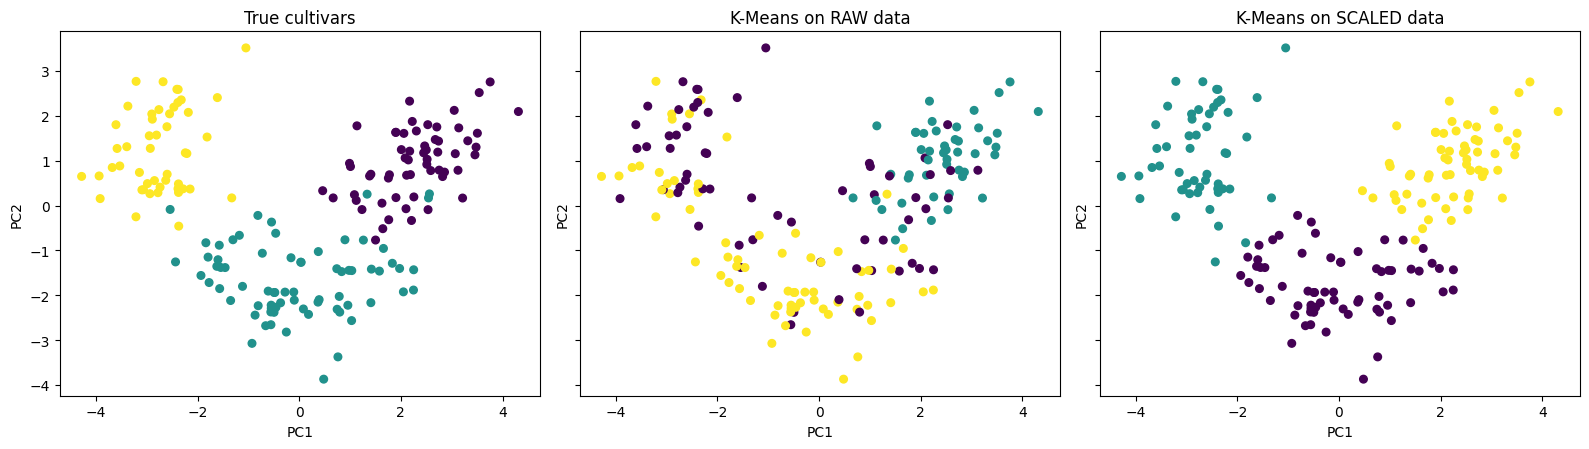

In [18]:
Z = PCA(n_components=2).fit_transform(Xw_s)                  # ONE PCA, computed on the scaled data
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True, sharey=True)
for a_, l, tt in zip(ax, [yw, lab_wr, lab_ws], ['True cultivars', 'K-Means on RAW data', 'K-Means on SCALED data']):
    a_.scatter(Z[:, 0], Z[:, 1], c=l, cmap='viridis', s=30)
    a_.set_title(tt); a_.set_xlabel('PC1'); a_.set_ylabel('PC2')
plt.tight_layout(); plt.show()

> **Interpretation:** (Colours are only labels, so the colour numbers differ between plots.) The raw clusters overlap and mix the true cultivars, because the distance is almost only Proline. The scaled clusters follow the three true cultivars closely (ARI 0.8975), so scaling gives the better clustering.

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

**(a)** With Income in dollars (15,000 to 137,000) against Age (18 to 70), the distance sqrt((dAge)^2 + (dIncome)^2) is controlled almost entirely by **Income**: an Age difference of 50 years is nothing next to an Income difference of 50,000, so the clustering becomes a clustering by Income alone (horizontal bands). The same customers gave different clusters: ARI raw k$ vs raw dollars = **0.4897**. After scaling, the unit no longer matters: ARI scaled k$ vs scaled dollars = **1.0**. Raw dollars vs scaled dollars = 0.3605 (and raw k$ vs scaled k$ = 0.7701, because even in k$ Income has the larger spread).

**(b)** **Proline** dominated the raw distance: its standard deviation is **314.0**, against 14.2 for magnesium (22 times bigger), 3.33 for alcalinity of ash and 0.124 for the smallest feature (non-flavanoid phenols), about 2,500 times smaller. ARI against the true cultivar: **0.3711 raw** and **0.8975 scaled**.

**(c)** The silhouette was 0.5711 on raw data and 0.2849 on scaled data. On raw data the distance is almost only Proline, so the points lie along one long axis and look compact and well separated by that axis, giving a high silhouette, but these groups do not follow the cultivars (ARI 0.37). The silhouette only measures how well the clusters fit *the distance used*, not whether that distance is meaningful. Raw and scaled data are different spaces with different distances (13 equally weighted features in the scaled space), so their silhouettes are not comparable.

**(d)** Scale whenever the features have different units or very different ranges or standard deviations (check `describe()` or the std of each column), as almost always in real data; I would skip scaling only when all features are in the same unit and the size differences are meaningful. I will not decide by comparing silhouettes between scaled and raw data, since that is not fair.

---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [19]:
extra = np.array([[400.0, 99.0]])
X_out = np.vstack([X2, extra])                               # 201 rows
m0 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
m1 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_out)
def show(model, name):
    order = np.argsort(model.cluster_centers_[:, 0])
    print(f'{name}: sizes (sorted by income) =', np.bincount(model.labels_)[order].tolist())
    print(pd.DataFrame(model.cluster_centers_[order].round(1), columns=['Income', 'Spending']).to_string())
show(m0, 'Without extra'); print(); show(m1, 'With extra   ')
print('\nARI on the original 200 customers:', round(adjusted_rand_score(m0.labels_, m1.labels_[:200]), 4))

Without extra: sizes (sorted by income) = [22, 23, 81, 39, 35]
   Income  Spending
0    25.7      79.4
1    26.3      20.9
2    55.3      49.5
3    86.5      82.1
4    88.2      17.1

With extra   : sizes (sorted by income) = [23, 100, 39, 38, 1]
   Income  Spending
0    26.3      20.9
1    48.3      56.5
2    86.5      82.1
3    87.0      18.6
4   400.0      99.0

ARI on the original 200 customers: 0.7532


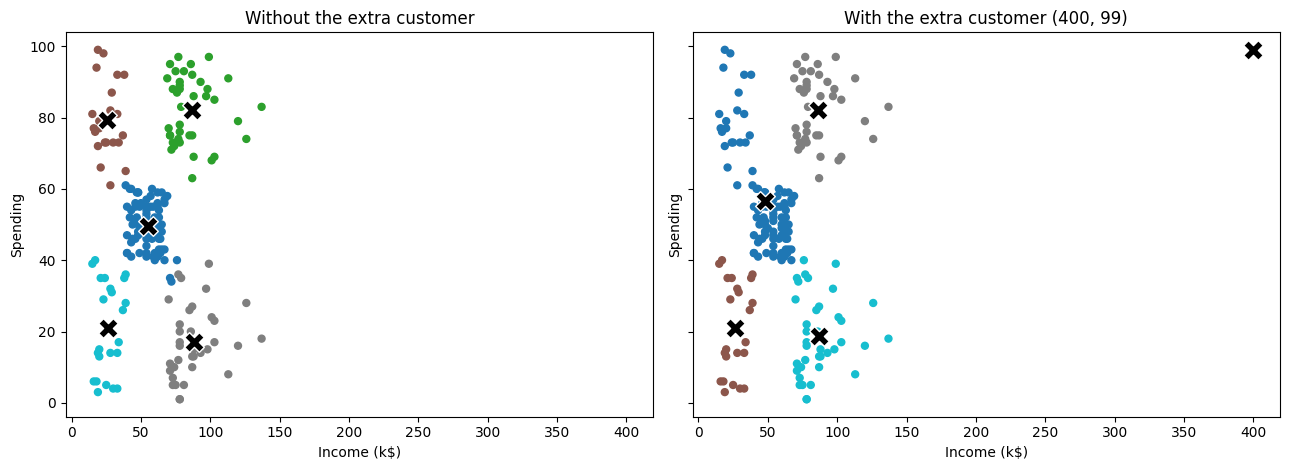

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True, sharey=True)
for a_, mm, XX, tt in zip(ax, [m0, m1], [X2, X_out], ['Without the extra customer', 'With the extra customer (400, 99)']):
    a_.scatter(XX[:, 0], XX[:, 1], c=mm.labels_, cmap='tab10', s=25)
    a_.scatter(*mm.cluster_centers_.T, c='black', marker='X', s=200, edgecolor='white')
    a_.set_title(tt); a_.set_xlabel('Income (k$)'); a_.set_ylabel('Spending')
plt.tight_layout(); plt.show()

> **Interpretation:** With the extra customer, one centroid is placed at (400, 99) (cluster of size 1) and the real customers are squeezed into four clusters: the low income/high spending group is absorbed in the centre cluster (size 100). The ARI on the original 200 customers is 0.7532.

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [21]:
d = m0.transform(X2).min(axis=1)                             # distance to own (nearest) centroid
d_extra = m0.transform(extra).min(axis=1)[0]
thr = d.mean() + 3 * d.std()
flag = d > thr
print(f'Mean distance = {d.mean():.2f}, std = {d.std():.2f}, threshold = mean + 3*std = {thr:.2f}')
print(f'Extra customer distance = {d_extra:.2f} -> flagged: {d_extra > thr}')
print(f'Real customers flagged  : {int(flag.sum())}')
top5 = df.assign(Cluster=m0.labels_, Distance=d.round(2)).sort_values('Distance', ascending=False).head(5)
display(top5[['CustomerID', 'Age', 'Income', 'Spending', 'Cluster', 'Distance']])
keep = ~flag
m2 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2[keep])
order = np.argsort(m2.cluster_centers_[:, 0])
print('\nRefit without flagged points: sizes (sorted by income) =', np.bincount(m2.labels_)[order].tolist(), '| points used:', int(keep.sum()))
print('ARI vs original model on the 200 customers (predict):', round(adjusted_rand_score(m0.labels_, m2.predict(X2)), 4))

Mean distance = 13.02, std = 7.26, threshold = mean + 3*std = 34.80
Extra customer distance = 313.92 -> flagged: True
Real customers flagged  : 4


,CustomerID,Age,Income,Spending,Cluster,Distance
199,200,30,137,83,1,50.47
198,199,32,137,18,3,48.81
197,198,32,126,74,1,40.29
196,197,45,126,28,3,39.34
195,196,35,120,79,1,33.61



Refit without flagged points: sizes (sorted by income) = [22, 23, 80, 37, 34] | points used: 196
ARI vs original model on the 200 customers (predict): 0.9847


> **Interpretation:** Mean distance 13.02, std 7.26, threshold 34.80. The extra customer (distance 313.92) is flagged. 4 real customers are flagged, the top five farthest are IDs 200, 199, 198, 197 and 196 (distances 50.47, 48.81, 40.29, 39.34 and 33.61; the last one is just below the threshold). All are customers with Income 120-137 k$. After removing the flagged points and refitting, the sizes are [22, 23, 80, 37, 34] and ARI = 0.9847 against the original model: the clustering is almost the same.

**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

**(a)** The extra customer (400, 99) got **a cluster of its own** (size 1, centroid (400, 99)), leaving only 4 clusters for the 200 real customers. Sizes sorted by income: before [22, 23, 81, 39, 35], after [23, 100, 39, 38, 1]. The **low income/high spending** group (22 customers, centroid (25.7, 79.4)) disappeared: it was merged with the centre group into one cluster of 100 customers with centroid (48.3, 56.5) (before: 81 customers at (55.3, 49.5)). The high income/low spending centroid moved from (88.2, 17.1) to (87.0, 18.6), while the low income/low spending (26.3, 20.9) and the high income/high spending (86.5, 82.1) groups were unchanged. ARI on the original 200 customers = **0.7532**. One customer (0.5% of the data) destroyed a real segment.

**(b)** The extra customer was detected clearly: distance 313.92 against a threshold of 34.80 (mean 13.02 + 3 x std 7.26), about 24 times the mean distance. The rule also flagged **4 real customers** (IDs 200, 199, 198, 197) with Income 126-137 k$ and Spending 83, 18, 74 and 28. They are **not data errors**: they are real, very high-income customers who lie at the edge of the high-income clusters (centroids at income about 86-88), so they deserve attention (probably VIP or high-potential customers).

**(c)** Two ways: (1) detect them with the distance rule, check them, and remove them before fitting (they can be assigned later with `predict`); (2) keep them but treat them separately, for example analyse them as their own special group or limit (cap) the extreme values. Risk of simply deleting: you may delete **real, valuable customers** (such as the 4 rich customers) and lose information; also the rule uses mean and std, which the outlier itself has already moved. After removing the 5 flagged points and refitting, the sizes were [22, 23, 80, 37, 34] and ARI against the original model = 0.9847.

---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [22]:
km6 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)   # K = 5 on Income & Spending, SEED = 42
df['Cluster'] = km6.labels_
df['Female'] = (df['Gender'] == 'Female').astype(int)
profile = df.groupby('Cluster').agg(Customers=('CustomerID', 'count'), Age=('Age', 'mean'),
                                    Income=('Income', 'mean'), Spending=('Spending', 'mean'),
                                    Pct_Female=('Female', lambda s: 100 * s.mean())).round(1).sort_values('Income')
display(profile)

,Customers,Age,Income,Spending,Pct_Female
Cluster,,,,,
2,22,25.3,25.7,79.4,59.1
4,23,45.2,26.3,20.9,60.9
0,81,42.7,55.3,49.5,59.3
1,39,32.7,86.5,82.1,53.8
3,35,41.1,88.2,17.1,45.7


In [23]:
def level(v, low, high):
    return 'Low' if v < low else ('High' if v >= high else 'Mid')
names = {c: f"{level(r.Income, 40, 70)} income / {level(r.Spending, 35, 65)} spending" for c, r in profile.iterrows()}
df['Segment'] = df['Cluster'].map(names)
print(df['Segment'].value_counts().to_string())

Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22


> **Interpretation:** The profile table (sorted by income) gives five clear groups. Sizes: Mid income / Mid spending 81 (40.5%), High / High 39 (19.5%), High income / Low spending 35 (17.5%), Low / Low 23 (11.5%) and Low income / High spending 22 (11.0%). Each segment gets a different name from the rule.

### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [24]:
ct = pd.crosstab(df['Segment'], df['Gender'], normalize='index').mul(100).round(1)
ct['Customers'] = df['Segment'].value_counts()
display(ct)
print('Overall % female:', round(100 * df['Female'].mean(), 1))
X3 = StandardScaler().fit_transform(df[['Age', 'Income', 'Spending']])
r3 = []
for k in range(2, 9):
    r3.append((k, silhouette_score(X3, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X3).labels_)))
t62 = pd.DataFrame(r3, columns=['K', 'Silhouette']).set_index('K'); display(t62.round(4))
best_k3 = int(t62['Silhouette'].idxmax()); print('Best K (3 scaled features):', best_k3)

Gender,Female,Male,Customers
Segment,,,
High income / High spending,53.8,46.2,39
High income / Low spending,45.7,54.3,35
Low income / High spending,59.1,40.9,22
Low income / Low spending,60.9,39.1,23
Mid income / Mid spending,59.3,40.7,81


Overall % female: 56.0


,Silhouette
K,
2,0.3355
3,0.3578
4,0.4040
5,0.4166
6,0.4284
7,0.4172
8,0.4082


Best K (3 scaled features): 6


> **Interpretation:** Women are 56.0% overall and between 45.7% and 60.9% in the segments, so Gender does not separate them. With scaled Age, Income and Spending the silhouette is highest at K = 6 (0.4284), slightly above K = 5 (0.4166).

### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [25]:
km3 = KMeans(n_clusters=best_k3, n_init=10, random_state=SEED).fit(X3)
df['Cluster3'] = km3.labels_
prof3 = df.groupby('Cluster3').agg(Customers=('CustomerID', 'count'), Age=('Age', 'mean'),
                                   Income=('Income', 'mean'), Spending=('Spending', 'mean')).round(1).sort_values('Age')
display(prof3)
print('ARI (3-feature vs 2-feature K=5):', round(adjusted_rand_score(df['Cluster3'], df['Cluster']), 4))
display(pd.crosstab(df['Cluster3'], df['Segment']))

,Customers,Age,Income,Spending
Cluster3,,,,
4,23,25.0,25.3,77.6
1,39,26.8,57.1,48.1
3,39,32.7,86.5,82.1
2,33,41.9,88.9,17.0
5,21,45.5,26.3,19.4
0,45,56.3,54.3,49.1


ARI (3-feature vs 2-feature K=5): 0.7002


Segment,High income / High spending,High income / Low spending,Low income / High spending,Low income / Low spending,Mid income / Mid spending
Cluster3,,,,,
0,0,1,0,1,43
1,0,2,0,0,37
2,0,32,0,0,1
3,39,0,0,0,0
4,0,0,22,1,0
5,0,0,0,21,0


> **Interpretation:** The 3-feature K=6 segmentation keeps four income/spending groups and splits the middle group by Age (mean Age 26.8 with 39 customers against 56.3 with 45 customers). ARI against the 2-feature K=5 segmentation is 0.7002: similar, but not the same.

**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

**(a)** Segment names and actions (from the profile table):

| Segment | Customers | Age / Income / Spending | Business name | Action |
|---|---|---|---|---|
| Low income / High spending | 22 | 25.3 / 25.7 / 79.4 | Young Trend Lovers | Loyalty points and affordable trend offers by social media |
| Low income / Low spending | 23 | 45.2 / 26.3 / 20.9 | Budget Savers | Low-cost clearance and essentials coupons; do not over-invest |
| Mid income / Mid spending | 81 | 42.7 / 55.3 / 49.5 | Everyday Shoppers | Seasonal bundles and 'spend more, save more' offers to raise basket size |
| High income / High spending | 39 | 32.7 / 86.5 / 82.1 | VIP Big Spenders | VIP card, early access to new collections, personal service |
| High income / Low spending | 35 | 41.1 / 88.2 / 17.1 | Untapped Wealthy | Premium and personalised invitations (events, dining); a short survey to learn why they do not spend |

**(b)** The **most valuable now** is *High income / High spending* (VIP Big Spenders): 39 customers (19.5%) with a high income (86.5) and the highest spending (82.1). The **biggest opportunity** is *High income / Low spending* (Untapped Wealthy): 35 customers (17.5%) with the same income (88.2) but a spending score 65 points lower (17.1 against 82.1); if they spent even like the middle group (about 50) the gain would be large.

**(c)** No, Gender does not separate the segments. Overall 56.0% are women; by segment: 53.8% (High/High), 45.7% (High/Low), 59.1% (Low/High), 60.9% (Low/Low), 59.3% (Mid/Mid). The differences are small (at most about 10 points) and the segments are small (22 to 81 customers), where one customer changes a percentage by about 3-5 points. Every segment contains both genders.

**(d)** Partly. With the best K = 6 on scaled Age, Income and Spending (silhouette 0.4284; K=5 gives 0.4166), the ARI against the 2-feature K=5 segmentation is 0.7002. The four income/spending groups stay almost the same (High/High 39, Low/High 23, ...) but Age **splits the middle group** into younger customers (39 customers, mean Age 26.8) and older customers (45 customers, mean Age 56.3) with nearly the same Income (57.1 and 54.3) and Spending (48.1 and 49.1). I would present the **2-feature K=5 segmentation**: it is clear on the Income-Spending plot, was the best K by both elbow and silhouette, is stable (100% best runs with n_init=10) and easy to turn into 5 actions. I would only mention the age split of the middle group as an extra insight. The silhouettes (0.5539 and 0.4284) cannot be compared because they come from different feature sets.

---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [26]:
out = df[['CustomerID', 'Age', 'Gender', 'Income', 'Spending', 'Cluster', 'Segment']]
out.to_csv('customer_segments.csv', index=False)
print(out['Segment'].value_counts().to_string())
out.head()

Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22


,CustomerID,Age,Gender,Income,Spending,Cluster,Segment
0,1,19,Male,15,39,4,Low income / Low spending
1,2,21,Male,15,81,2,Low income / High spending
2,3,20,Female,16,6,4,Low income / Low spending
3,4,23,Female,16,77,2,Low income / High spending
4,5,31,Female,17,40,4,Low income / Low spending


> **Interpretation:** The file `customer_segments.csv` contains 200 customers with their Cluster and Segment; the printed counts (81, 39, 35, 23, 22) match the profile table.

**Executive Summary**

1. **K = 5** on Income and Spending: the elbow bends at 5 (inertia drop 29,231 from K=4 to 5, but only 7,215 from 5 to 6) and the silhouette is highest at K=5 (0.5539).
2. **Segments (size):** Everyday Shoppers (Mid/Mid) 81, VIP Big Spenders (High/High) 39, Untapped Wealthy (High income/Low spending) 35, Budget Savers (Low/Low) 23, Young Trend Lovers (Low income/High spending) 22.
3. **Actions:** Everyday Shoppers - seasonal bundles; VIP Big Spenders - VIP card and early access; Untapped Wealthy - premium invitations and a short survey (biggest opportunity); Budget Savers - low-cost coupons; Young Trend Lovers - loyalty points and affordable trend offers.
4. **Scaling:** Income (std 26.3) and Spending (std 25.8) are on similar scales, so raw values were used; Part 4 proved that scaling is essential when sizes differ (unit change: ARI 0.4897 raw, 1.0 scaled; Wine ARI 0.3711 raw, 0.8975 scaled).
5. **Stability:** k-means++ with `n_init=10` gave the best inertia (44,448.5) in 30 of 30 seeds, so the segments are stable.
6. **Outliers:** one extreme customer (400, 99) destroyed a real segment (ARI 0.7532); the 3-std rule caught it and flagged 4 real very-high-income customers (126-137 k$), which are real VIPs and were kept in the final segmentation.
7. **Age:** adding Age (K=6) only splits the middle group into younger and older shoppers (ARI 0.7002 with the 2-feature result); Gender does not separate the segments.
8. **Limitation:** only 200 customers and a mall-assigned Spending Score, and K-Means assumes round groups; the segments should be validated with real purchase data.

**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

**(a)** The most surprising result: **one single extra customer** (400, 99), only 0.5% of the data, replaced a real segment with its own cluster of size 1 and dropped the agreement with the original clustering to ARI = 0.7532. Also surprising: on the Wine data the silhouette was **higher for the worse clustering** (0.5711 raw against 0.2849 scaled, while ARI was 0.3711 against 0.8975), and a random start reached the best inertia in only 10 of 30 runs.

**(b)** I would (1) repeat the 30-seed stability test for the 3-feature K=6 solution, (2) test the distance rule with other thresholds (for example mean + 2 std) and see how the segments change, (3) try K-Means on Age and Spending or on Age and Income to look for other customer views, (4) draw the 3-feature clusters with PCA, and (5) check the segments with real purchase data and not only the mall's Spending Score.

---